Помогает ли регуляризация игнорировать шум?

Я добавил к 64 пикселям рукописной цифры ещё 64 случайных признака. Они независимы от метки. Если менять только эти числа, изображение остаётся прежним. Меня интересуют два вопроса: как часто сеть после этого меняет ответ и можно ли уменьшить эту зависимость с помощью L1 или L2?

Сравниваю одну архитектуру 128 - 32 - 10 в шести условиях. В контрольном варианте последние 64 входа заполнены нулями, в экспериментальном - шумом. Для каждого варианта проверяю обучение без штрафа, с L1 и с L2. Гипотеза: регуляризация ослабит влияние шума; её эффект на точность проверяю отдельно.

Основная реализация обучения использует PyTorch. Для воспроизводимости предусмотрен контрольный расчёт в NumPy с явными градиентами. Первая ячейка указывает, какой реализацией получены текущие результаты.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

try:
    import torch
    from torch import nn
except ModuleNotFoundError as error:
    if error.name != "torch":
        raise
    torch = None

if torch is not None:
    torch.set_num_threads(1)
print("Реализация обучения:", "PyTorch" if torch is not None else "NumPy (контрольный расчёт)")

Реализация обучения: PyTorch


Выборки и масштаб признаков

В каждом классе беру 40 примеров для обучения и 30 для валидации. Остальные откладываю для теста. Постоянные пиксели после центрирования остаются нулевыми; масштаб остальных ограничиваю снизу, чтобы редкие ненулевые пиксели не получали слишком большой вес. Шум имеет стандартное нормальное распределение. Он фиксирован для каждого объекта и общий для всех трёх режимов регуляризации.

In [2]:
digits = load_digits()
pixels = digits.data / 16
labels = digits.target
rng = np.random.default_rng(42)
groups = [rng.permutation(np.flatnonzero(labels == k)) for k in range(10)]
train = np.concatenate([g[:40] for g in groups])
val = np.concatenate([g[40:70] for g in groups])
test = np.concatenate([g[70:] for g in groups])
assert len(set(train) | set(val) | set(test)) == len(labels)
pixels = (pixels - pixels[train].mean(0)) / np.maximum(pixels[train].std(0), 0.1)
noise = rng.normal(size=pixels.shape)
inputs = {"Нули": np.column_stack((pixels, np.zeros_like(noise))),
          "Шум": np.column_stack((pixels, noise))}
print("Обучение, валидация, тест:", len(train), len(val), len(test))

Обучение, валидация, тест: 400 300 1097


Обучение и выбор силы штрафа

Оптимизирую среднюю кросс-энтропию плюс λ, умноженную на сумму модулей весов (L1) или сумму квадратов (L2). Штраф действует на обе матрицы весов. Смещения свободны. Для всех моделей использую одинаковые стартовые параметры, полную обучающую выборку и 200 шагов SGD с импульсом 0.9. Коэффициент выбираю отдельно для типа входа и штрафа по минимальной валидационной кросс-энтропии без штрафа.

In [3]:
init_rng = np.random.default_rng(7)
initial = [init_rng.normal(0, 0.08, (128, 32)), np.zeros(32),
           init_rng.normal(0, 0.15, (32, 10)), np.zeros(10)]
rate, momentum, steps = 0.04, 0.9, 200
grid = {"Без штрафа": [0.0], "L1": [0.0001, 0.0005, 0.002],
        "L2": [0.0005, 0.002, 0.01]}

def torch_fit(x, y, kind, strength):
    model = nn.Sequential(nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, 10)).double()
    with torch.no_grad():
        for layer, w, b in [(model[0], *initial[:2]), (model[2], *initial[2:])]:
            layer.weight.copy_(torch.from_numpy(w.T))
            layer.bias.copy_(torch.from_numpy(b))
    opt = torch.optim.SGD(model.parameters(), lr=rate, momentum=momentum)
    features, targets = torch.from_numpy(x), torch.from_numpy(y).long()
    for _ in range(steps):
        opt.zero_grad()
        loss = nn.functional.cross_entropy(model(features), targets)
        weights = (model[0].weight, model[2].weight)
        if kind == "L1":
            loss = loss + strength * sum(w.abs().sum() for w in weights)
        if kind == "L2":
            loss = loss + strength * sum(w.square().sum() for w in weights)
        loss.backward()
        opt.step()
    return [p.detach().numpy().T.copy() for p in model.parameters()]

def numpy_fit(x, y, kind, strength):
    params = [p.copy() for p in initial]
    velocity = [np.zeros_like(p) for p in params]
    for _ in range(steps):
        w, b, v, d = params
        h = np.maximum(0, x @ w + b)
        logits = h @ v + d
        prob = np.exp(logits - logits.max(axis=1, keepdims=True))
        prob /= prob.sum(axis=1, keepdims=True)
        prob[np.arange(len(y)), y] -= 1
        prob /= len(y)
        dh = (prob @ v.T) * (h > 0)
        grads = [x.T @ dh, dh.sum(0), h.T @ prob, prob.sum(0)]
        for i in (0, 2):
            if kind == "L1":
                grads[i] += strength * np.sign(params[i])
            if kind == "L2":
                grads[i] += 2 * strength * params[i]
        for p, speed, grad in zip(params, velocity, grads):
            speed *= momentum
            speed += grad
            p -= rate * speed
    return params

def predict_scores(x, params):
    w, b, v, d = params
    return np.maximum(0, x @ w + b) @ v + d

def validation_loss(logits, y):
    return np.mean(np.logaddexp.reduce(logits, axis=1) - logits[np.arange(len(y)), y])

fit = torch_fit if torch is not None else numpy_fit
best = {}
for mode, features in inputs.items():
    for kind, choices in grid.items():
        candidates = []
        for strength in choices:
            params = fit(features[train], labels[train], kind, strength)
            ce = validation_loss(predict_scores(features[val], params), labels[val])
            candidates.append((ce, strength, params))
        best[mode, kind] = min(candidates, key=lambda trial: trial[0])
print("Выбрано моделей:", len(best))

Выбрано моделей: 6


Точность и устойчивость

Для шумовых моделей сравниваю исходный прогноз с 20 прогнозами на той же цифре и свежих независимых наборах шума. Считаю процент тестовых цифр, у которых хотя бы раз изменился предсказанный класс. Все модели получают одинаковые замены. Для контрольных моделей измеряю точность в исходном режиме с нулями. Веса первого слоя анализирую отдельно по двум группам входов; порог близости к нулю фиксирую заранее: |w| < 0.01.

In [4]:
noise_rng = np.random.default_rng(2026)
replacements = [np.column_stack((pixels[test], noise_rng.normal(size=pixels[test].shape)))
                for _ in range(20)]
rows = []
for (mode, kind), (ce, strength, params) in best.items():
    pred = predict_scores(inputs[mode][test], params).argmax(1)
    accuracy = 100 * np.mean(pred == labels[test])
    flips = np.nan
    if mode == "Шум":
        changed = [predict_scores(new_x, params).argmax(1) != pred for new_x in replacements]
        flips = 100 * np.any(changed, axis=0).mean()
    w = params[0]
    rows.append([mode, kind, strength, ce, accuracy, flips,
                 100 * (abs(w[:64]) < 0.01).mean(), 100 * (abs(w[64:]) < 0.01).mean()])
table = pd.DataFrame(rows, columns=["Вход", "Штраф", "λ", "CE val", "Точность, %",
                     "Смена, %", "Малые w пикселей, %", "Малые w шума, %"]).set_index(["Вход", "Штраф"])
print(table.round(3).to_string(na_rep="—"))

                     λ  CE val  Точность, %  Смена, %  Малые w пикселей, %  Малые w шума, %
Вход Штраф                                                                                 
Нули Без штрафа  0.000   0.183       93.892         —                7.422           10.352
     L1          0.000   0.176       94.439         —               25.928           44.873
     L2          0.002   0.172       94.257         —                8.350           13.477
Шум  Без штрафа  0.000   0.247       90.611    26.618                7.178            7.422
     L1          0.000   0.223       92.252    21.149               27.686           35.352
     L2          0.000   0.243       90.884    26.071                7.275            8.105


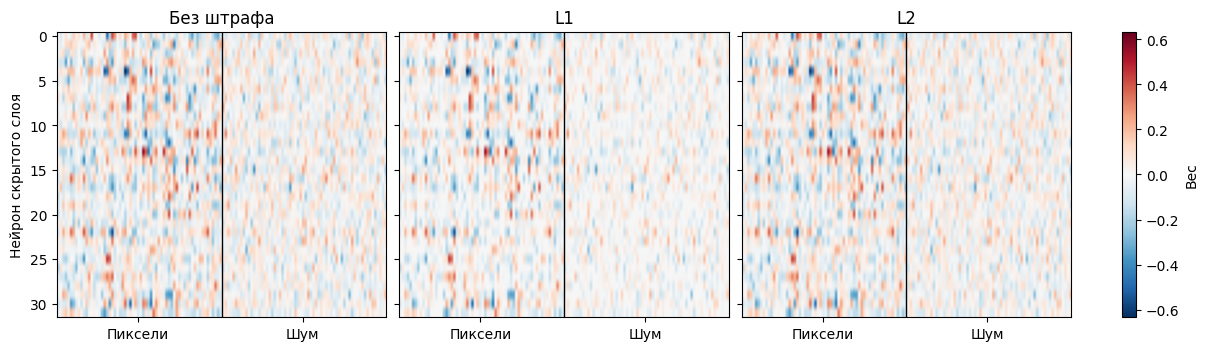

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True, layout="constrained")
matrices = [best["Шум", k][2][0].T for k in grid]
limit = max(abs(w).max() for w in matrices)
for ax, name, matrix in zip(axes, grid, matrices):
    im = ax.imshow(matrix, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.axvline(63.5, color="black", linewidth=1)
    ax.set(title=name, xticks=[31, 95], xticklabels=["Пиксели", "Шум"])
axes[0].set_ylabel("Нейрон скрытого слоя")
fig.colorbar(im, ax=axes.tolist(), label="Вес")
plt.show()

Вывод

In [6]:
noisy = table.loc["Шум"]
baseline = noisy.loc["Без штрафа"]
print(f"Без штрафа добавление шума изменило точность на "
      f"{baseline['Точность, %'] - table.loc[('Нули', 'Без штрафа'), 'Точность, %']:+.1f} п.п.")
for kind in ("L1", "L2"):
    row = noisy.loc[kind]
    print(f"{kind}: изменение точности {row['Точность, %'] - baseline['Точность, %']:+.1f} п.п.; "
          f"изменение доли смен ответа {row['Смена, %'] - baseline['Смена, %']:+.1f} п.п.; "
          f"малых весов у шумовых входов {row['Малые w шума, %']:.1f}%.")
print("Минимальная доля смен ответа:", noisy["Смена, %"].idxmin())
print("Максимальная точность:", noisy["Точность, %"].idxmax())

Без штрафа добавление шума изменило точность на -3.3 п.п.
L1: изменение точности +1.6 п.п.; изменение доли смен ответа -5.5 п.п.; малых весов у шумовых входов 35.4%.
L2: изменение точности +0.3 п.п.; изменение доли смен ответа -0.5 п.п.; малых весов у шумовых входов 8.1%.
Минимальная доля смен ответа: L1
Максимальная точность: L1


Уменьшение доли смен ответа означает, что при этом испытании прогноз устойчивее к случайным входам. Его полезно читать вместе с точностью: постоянный неправильный ответ тоже был бы устойчивым. Тепловая карта показывает величины отдельных весов, а смена предсказаний измеряет поведение всей сети.